# CyberThreat AI v2
## Binary Classification: BENIGN vs ATTACK

**Objective:** Classify network traffic as benign or malicious using the CIC-IDS2017 dataset.

### Models evaluated
1. Majority-class baseline
2. Logistic Regression
3. Decision Tree
4. Random Forest

### Evaluation approach
Identical feature rows are kept within the same partition using a group-based train-test split. This helps prevent duplicate-feature leakage between training and testing data.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

## 1. Load the cleaned master dataset

In [2]:
DATA_PATH = Path("../data/master_dataset.csv")
df = pd.read_csv(DATA_PATH, low_memory=False)

df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (42220, 77)


## 2. Understand the dataset

In [3]:
display(df.head())
print("Rows and columns:", df.shape)
df.info()

print("\\nOriginal attack categories:")
display(df["Label"].value_counts())

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.3-192.168.10.9-53-58567-17,192.168.10.9,58567.0,192.168.10.3,53.0,17.0,2017-07-07 02:09:00,62285.0,2.0,2.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
1,172.16.0.1-192.168.10.50-50497-80-6,172.16.0.1,50497.0,192.168.10.50,80.0,6.0,2017-07-07 04:15:00,1327496.0,3.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS,Friday
2,192.168.10.5-67.217.177.158-52869-443-6,67.217.177.158,443.0,192.168.10.5,52869.0,6.0,2017-07-06 12:02:00,5.0,3.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Thursday
3,192.168.10.15-192.168.10.50-53502-22-6,192.168.10.15,53502.0,192.168.10.50,22.0,6.0,2017-07-06 10:32:00,156.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Thursday
4,172.16.0.1-192.168.10.50-59884-21-6,172.16.0.1,59884.0,192.168.10.50,21.0,6.0,2017-07-04 10:18:00,9520699.0,9.0,15.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,FTP-Patator,Tuesday


Rows and columns: (42220, 77)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42220 entries, 0 to 42219
Data columns (total 77 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Flow ID                      42220 non-null  object        
 1   Source IP                    42220 non-null  object        
 2   Source Port                  42220 non-null  float64       
 3   Destination IP               42220 non-null  object        
 4   Destination Port             42220 non-null  float64       
 5   Protocol                     42220 non-null  float64       
 6   Timestamp                    42220 non-null  datetime64[ns]
 7   Flow Duration                42220 non-null  float64       
 8   Total Fwd Packets            42220 non-null  float64       
 9   Total Backward Packets       42220 non-null  float64       
 10  Total Length of Fwd Packets  42220 non-null  float64       
 11  Total Lengt

Label
BENIGN                        20000
DDoS                           4000
DoS Hulk                       4000
PortScan                       4000
FTP-Patator                    1500
DoS Slowhttptest               1500
DoS GoldenEye                  1500
SSH-Patator                    1500
DoS slowloris                  1500
Web Attack - Brute Force       1000
Bot                            1000
Web Attack - XSS                652
Infiltration                     36
Web Attack - Sql Injection       21
Heartbleed                       11
Name: count, dtype: int64

## 3. Create the binary target

In [4]:
df["Binary_Label"] = np.where(df["Label"] == "BENIGN", 0, 1)

print("Binary target distribution:")
display(df["Binary_Label"].value_counts())

print("\\nPercentage distribution:")
display(df["Binary_Label"].value_counts(normalize=True).mul(100).round(2))

Binary target distribution:


Binary_Label
1    22220
0    20000
Name: count, dtype: int64

\nPercentage distribution:


Binary_Label
1    52.63
0    47.37
Name: proportion, dtype: float64

## 4. Prepare features and target

In [5]:
drop_columns = [
    "Flow ID", "Source IP", "Destination IP", "Timestamp",
    "Day", "Label", "Binary_Label", "Source Port", "Destination Port"
]

X = df.drop(columns=drop_columns)
y = df["Binary_Label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\\nFeature data types:")
display(X.dtypes.value_counts())

non_numeric = X.select_dtypes(exclude=["number"]).columns
print("Non-numeric columns:", list(non_numeric))

Features shape: (42220, 69)
Target shape: (42220,)
\nFeature data types:


float64    69
Name: count, dtype: int64

Non-numeric columns: []


## 5. Data quality checks

In [6]:
print("Missing values:", X.isnull().sum().sum())
print("Infinite values:", np.isinf(X.select_dtypes(include="number")).sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())

Missing values: 0
Infinite values: 0
Duplicate feature rows: 6607


## 6. Investigate duplicate feature rows and conflicting labels

In [7]:
duplicate_mask = X.duplicated(keep=False)
duplicate_labels = df.loc[duplicate_mask, "Label"]

print("Labels among duplicate feature rows:")
display(duplicate_labels.value_counts())
print("Unique labels among duplicate feature rows:", duplicate_labels.nunique())

duplicate_groups = df.groupby(list(X.columns), dropna=False)["Label"].nunique()
conflicting_groups = duplicate_groups[duplicate_groups > 1]

print("Duplicate feature groups:", (duplicate_groups > 1).sum())
print("Groups with conflicting original labels:", len(conflicting_groups))
print("Groups with conflicting binary labels:",
      (df.groupby(list(X.columns), dropna=False)["Binary_Label"].nunique() > 1).sum())

Labels among duplicate feature rows:


Label
PortScan                    3926
BENIGN                      1137
DoS Hulk                     864
SSH-Patator                  669
FTP-Patator                  324
Bot                          290
DoS slowloris                 98
DoS Slowhttptest              73
Web Attack - Brute Force      36
Name: count, dtype: int64

Unique labels among duplicate feature rows: 9
Duplicate feature groups: 8
Groups with conflicting original labels: 8
Groups with conflicting binary labels: 8


## 7. Remove conflicting feature groups

In [8]:
conflict_keys = (
    df.groupby(list(X.columns), dropna=False)["Binary_Label"]
    .nunique()
)
conflict_keys = conflict_keys[conflict_keys > 1].index

conflict_mask = pd.MultiIndex.from_frame(X).isin(conflict_keys)

X_clean = X.loc[~conflict_mask].copy()
y_clean = y.loc[~conflict_mask].copy()

print("Original records:", len(X))
print("Records after removing conflicting groups:", len(X_clean))
print("Removed records:", len(X) - len(X_clean))

print("\\nCleaned target distribution:")
display(y_clean.value_counts())
display(y_clean.value_counts(normalize=True).mul(100).round(2))

Original records: 42220
Records after removing conflicting groups: 42034
Removed records: 186
\nCleaned target distribution:


Binary_Label
1    22044
0    19990
Name: count, dtype: int64

Binary_Label
1    52.44
0    47.56
Name: proportion, dtype: float64

## 8. Group-based train-test split

In [9]:
# Factorize exact feature-row combinations so identical feature rows share a group.
groups = pd.factorize(pd.MultiIndex.from_frame(X_clean))[0]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(splitter.split(X_clean, y_clean, groups=groups))

X_train = X_clean.iloc[train_idx].copy()
X_test = X_clean.iloc[test_idx].copy()
y_train = y_clean.iloc[train_idx].copy()
y_test = y_clean.iloc[test_idx].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\\nTraining target distribution:")
display(y_train.value_counts())

print("\\nTesting target distribution:")
display(y_test.value_counts())

Training features: (33764, 69)
Testing features: (8270, 69)
\nTraining target distribution:


Binary_Label
1    17892
0    15872
Name: count, dtype: int64

\nTesting target distribution:


Binary_Label
1    4152
0    4118
Name: count, dtype: int64

### Verify duplicate-feature leakage

In [10]:
train_keys = pd.MultiIndex.from_frame(X_train)
test_keys = pd.MultiIndex.from_frame(X_test)

overlap = test_keys.isin(train_keys)

print("Identical test rows found in training:", overlap.sum())
print("Overlap percentage:", round(overlap.mean() * 100, 4), "%")

assert overlap.sum() == 0, "Duplicate feature rows overlap between train and test."

Identical test rows found in training: 0
Overlap percentage: 0.0 %


## 9. Majority-class baseline

In [11]:
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_metrics = {
    "Model": "Majority-Class Baseline",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, baseline_predictions, zero_division=0)
}

display(pd.DataFrame([baseline_metrics]).round(4))
print(classification_report(
    y_test, baseline_predictions,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

,Model,Accuracy,Precision,Recall,F1 Score
0,Majority-Class Baseline,0.5021,0.5021,1.0,0.6685


              precision    recall  f1-score   support

      BENIGN       0.00      0.00      0.00      4118
      ATTACK       0.50      1.00      0.67      4152

    accuracy                           0.50      8270
   macro avg       0.25      0.50      0.33      8270
weighted avg       0.25      0.50      0.34      8270



## 10. Logistic Regression

In [12]:
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression evaluation")
print("Accuracy:", round(accuracy_score(y_test, lr_predictions), 4))
print("Precision:", round(precision_score(y_test, lr_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, lr_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, lr_predictions, zero_division=0), 4))

print(classification_report(
    y_test, lr_predictions,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

Logistic Regression evaluation
Accuracy: 0.8779
Precision: 0.8383
Recall: 0.9376
F1 Score: 0.8852
              precision    recall  f1-score   support

      BENIGN       0.93      0.82      0.87      4118
      ATTACK       0.84      0.94      0.89      4152

    accuracy                           0.88      8270
   macro avg       0.88      0.88      0.88      8270
weighted avg       0.88      0.88      0.88      8270



## 11. Decision Tree

In [13]:
dt_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)

print("Decision Tree evaluation")
print("Accuracy:", round(accuracy_score(y_test, dt_predictions), 4))
print("Precision:", round(precision_score(y_test, dt_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, dt_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, dt_predictions, zero_division=0), 4))

print(classification_report(
    y_test, dt_predictions,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

dt_train_predictions = dt_model.predict(X_train)
print("Training Accuracy:", round(accuracy_score(y_train, dt_train_predictions), 4))
print("Testing Accuracy:", round(accuracy_score(y_test, dt_predictions), 4))

Decision Tree evaluation
Accuracy: 0.9948
Precision: 0.993
Recall: 0.9966
F1 Score: 0.9948
              precision    recall  f1-score   support

      BENIGN       1.00      0.99      0.99      4118
      ATTACK       0.99      1.00      0.99      4152

    accuracy                           0.99      8270
   macro avg       0.99      0.99      0.99      8270
weighted avg       0.99      0.99      0.99      8270

Training Accuracy: 1.0
Testing Accuracy: 0.9948


### Decision Tree feature importance

In [14]:
dt_importance = pd.Series(
    dt_model.named_steps["classifier"].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(dt_importance.head(15).to_frame("Importance"))

,Importance
Bwd Packet Length Min,0.303927
Init_Win_bytes_backward,0.185572
Average Packet Size,0.118285
Init_Win_bytes_forward,0.105379
min_seg_size_forward,0.057186
Flow IAT Min,0.040565
Bwd Header Length,0.028366
Bwd Packet Length Mean,0.028227
Fwd IAT Min,0.025009
Flow Bytes/s,0.019612


## 12. Random Forest

In [15]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

print("Random Forest evaluation")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, rf_predictions, zero_division=0), 4))

print(classification_report(
    y_test, rf_predictions,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

rf_train_predictions = rf_model.predict(X_train)
print("Training Accuracy:", round(accuracy_score(y_train, rf_train_predictions), 4))
print("Testing Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))

Random Forest evaluation
Accuracy: 0.996
Precision: 0.9969
Recall: 0.9952
F1 Score: 0.996
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      4118
      ATTACK       1.00      1.00      1.00      4152

    accuracy                           1.00      8270
   macro avg       1.00      1.00      1.00      8270
weighted avg       1.00      1.00      1.00      8270

Training Accuracy: 1.0
Testing Accuracy: 0.996


### Random Forest confusion matrix

Confusion Matrix:


,Predicted BENIGN,Predicted ATTACK
Actual BENIGN,4105,13
Actual ATTACK,20,4132


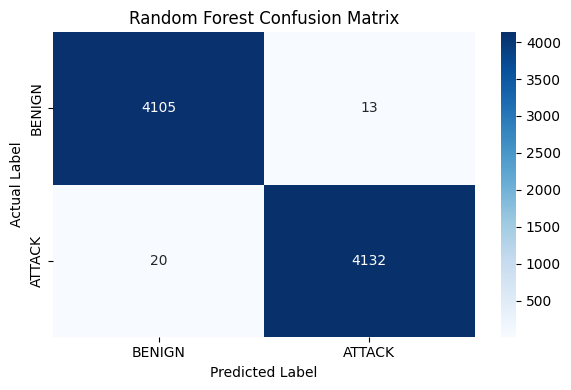

In [16]:
rf_cm = confusion_matrix(y_test, rf_predictions)

print("Confusion Matrix:")
display(pd.DataFrame(
    rf_cm,
    index=["Actual BENIGN", "Actual ATTACK"],
    columns=["Predicted BENIGN", "Predicted ATTACK"]
))

plt.figure(figsize=(6, 4))
sns.heatmap(
    rf_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["BENIGN", "ATTACK"],
    yticklabels=["BENIGN", "ATTACK"]
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

## 13. Model comparison

In [17]:
model_comparison = pd.DataFrame([
    baseline_metrics,
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_predictions),
        "Precision": precision_score(y_test, lr_predictions, zero_division=0),
        "Recall": recall_score(y_test, lr_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, lr_predictions, zero_division=0)
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, dt_predictions),
        "Precision": precision_score(y_test, dt_predictions, zero_division=0),
        "Recall": recall_score(y_test, dt_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, dt_predictions, zero_division=0)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(y_test, rf_predictions, zero_division=0),
        "Recall": recall_score(y_test, rf_predictions, zero_division=0),
        "F1 Score": f1_score(y_test, rf_predictions, zero_division=0)
    }
])

display(model_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Majority-Class Baseline,0.5021,0.5021,1.0000,0.6685
1,Logistic Regression,0.8779,0.8383,0.9376,0.8852
2,Decision Tree,0.9948,0.9930,0.9966,0.9948
3,Random Forest,0.9960,0.9969,0.9952,0.9960


## 14. Random Forest feature importance

,Importance
Init_Win_bytes_forward,0.114076
Init_Win_bytes_backward,0.059495
Packet Length Std,0.036407
Packet Length Variance,0.035438
Bwd Packet Length Min,0.032360
Min Packet Length,0.031830
Bwd Packet Length Std,0.031404
Protocol,0.030618
Avg Fwd Segment Size,0.029157
Fwd Packet Length Min,0.028997


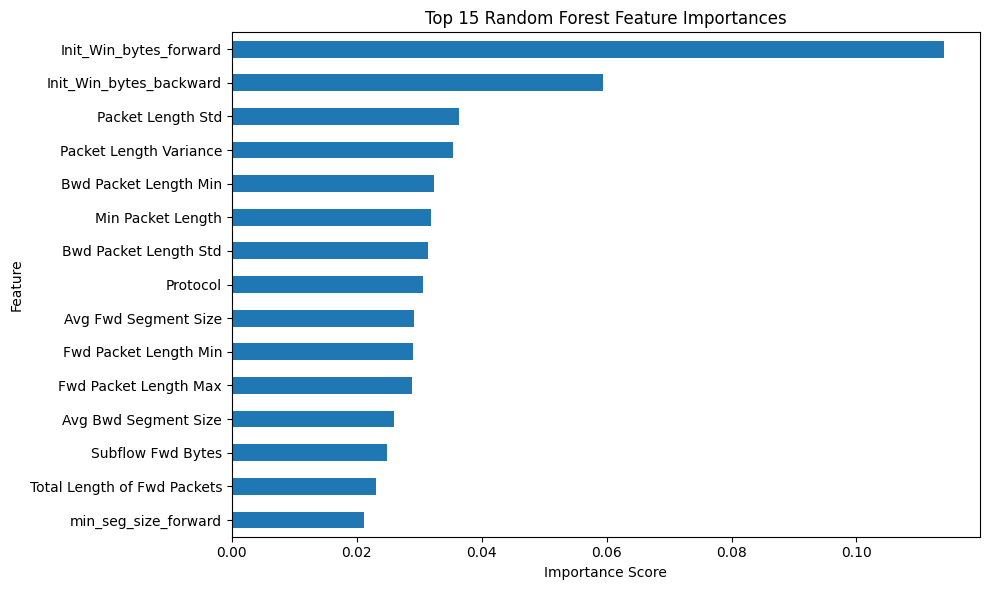

In [18]:
rf_importances = pd.Series(
    rf_model.named_steps["classifier"].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(rf_importances.head(15).to_frame("Importance"))

plt.figure(figsize=(10, 6))
rf_importances.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Permutation importance

In [19]:
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="f1",
    n_jobs=-1
)

perm_importance = pd.Series(
    perm_result.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

display(perm_importance.head(15).to_frame("Permutation Importance"))

,Permutation Importance
Init_Win_bytes_forward,0.035855
Init_Win_bytes_backward,0.011579
min_seg_size_forward,0.009090
Fwd IAT Min,0.005531
URG Flag Count,0.004546
Fwd Header Length,0.001019
Subflow Fwd Bytes,0.000388
Total Length of Fwd Packets,0.000387
Total Fwd Packets,0.000291
Avg Fwd Segment Size,0.000268


### Save feature importance results

In [20]:
feature_importance_df = pd.DataFrame({
    "Feature": rf_importances.index,
    "Built_in_Importance": rf_importances.values,
    "Permutation_Importance": perm_importance.reindex(rf_importances.index).values
})

REPORTS_DIR = Path("../reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

feature_importance_df.to_csv(
    REPORTS_DIR / "feature_importance.csv",
    index=False
)

print("Feature importance report saved:", REPORTS_DIR / "feature_importance.csv")

Feature importance report saved: ..\reports\feature_importance.csv


## 15. Performance by day

In [21]:
test_days = df.loc[X_test.index, "Day"]
day_results = []

for day in sorted(test_days.dropna().unique()):
    mask = test_days == day
    y_day = y_test.loc[mask]
    pred_day = rf_predictions[mask.to_numpy()]

    day_results.append({
        "Day": day,
        "Records": int(mask.sum()),
        "Accuracy": accuracy_score(y_day, pred_day),
        "Attack Recall": recall_score(y_day, pred_day, zero_division=0),
        "F1 Score": f1_score(y_day, pred_day, zero_division=0)
    })

day_performance = pd.DataFrame(day_results)
display(day_performance.round(4))

,Day,Records,Accuracy,Attack Recall,F1 Score
0,Friday,2474,0.9964,0.9964,0.9973
1,Monday,750,0.9947,0.0000,0.0000
2,Thursday,1219,0.9926,0.9762,0.9865
3,Tuesday,1431,0.9972,0.9983,0.9967
4,Wednesday,2396,0.9971,0.9968,0.9977


### Test-set class distribution by day

In [22]:
day_class_counts = pd.crosstab(
    test_days,
    y_test.map({0: "BENIGN", 1: "ATTACK"})
)
display(day_class_counts)

Binary_Label,ATTACK,BENIGN
Day,,
Friday,1655,819
Monday,0,750
Thursday,336,883
Tuesday,606,825
Wednesday,1555,841


## 16. Final evaluation summary

In [23]:
print("Test records:", len(y_test))
print("Actual BENIGN:", (y_test == 0).sum())
print("Actual ATTACK:", (y_test == 1).sum())

print("\\nBaseline predictions:")
print("BENIGN:", (baseline_predictions == 0).sum())
print("ATTACK:", (baseline_predictions == 1).sum())

display(model_comparison.round(4))

Test records: 8270
Actual BENIGN: 4118
Actual ATTACK: 4152
\nBaseline predictions:
BENIGN: 0
ATTACK: 8270


,Model,Accuracy,Precision,Recall,F1 Score
0,Majority-Class Baseline,0.5021,0.5021,1.0000,0.6685
1,Logistic Regression,0.8779,0.8383,0.9376,0.8852
2,Decision Tree,0.9948,0.9930,0.9966,0.9948
3,Random Forest,0.9960,0.9969,0.9952,0.9960


## 17. Conclusion

The models were evaluated using a group-based train-test split to prevent identical feature rows from appearing in both partitions. The majority-class baseline provides a reference point, while Logistic Regression, Decision Tree, and Random Forest are compared using accuracy, precision, recall, and F1-score.

The results are specific to this dataset and split. High performance should not be interpreted as guaranteed real-world network intrusion detection performance. Additional validation using different capture periods, environments, or network sources would be required to assess generalization.